# Settings

In [160]:
run_beamforming = True
beamform_interpolated = True

parameters_file_path = "./parameters/003_simulation_template.json"

#virtual space settings

blood_density = 1060
frames = 100

# Imports

In [161]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import json
from scipy import signal

# Import parameters

In [162]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [163]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    return params

In [164]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.010008000000000001 m


# Creating reflector object

In [165]:
virtual_space = np.zeros((params["rf"]["samples"], params["array"]["length"]))

In [166]:
angle = 25
vein_length = 0.003
vein_diameter = 0.0001

vein_density = 1200 #nb of possible globules for the vein

vein = np.random.rand(int(np.sqrt(vein_density)), int(np.sqrt(vein_density)))

for i in range(vein.shape[0]):
    for j in range(vein.shape[1]):
        if vein[i][j] >= 0.5:
            vein[i][j] = 1
        else:
            vein[i][j] = 0

samples_required_x = int(vein_diameter / params["array"]["pitch"])
print(f"Samples required for diameter: {samples_required_x}")

samples_required_y = int((vein_diameter / C)* params["rf"]["sampling_rate"])
print(f"Samples required for diameter: {samples_required_y}")

starting_x = 40 * params["array"]["pitch"] #mm
starting_y = 0.005 #mm

starting_x_idx = int(starting_x / params["array"]["pitch"]) #position / step gives the index
starting_y_idx = int((starting_y / C) * params["rf"]["sampling_rate"]) #position / step gives the index

print(f"Starting x : {starting_x} m / Starting x idx : {starting_x_idx}")
print(f"Starting y : {starting_y} s / Starting y idx : {starting_y_idx}")

Samples required for diameter: 1
Samples required for diameter: 4
Starting x : 0.0036000000000000003 m / Starting x idx : 40
Starting y : 0.005 s / Starting y idx : 208


In [167]:
for i in range(0, vein.shape[0]):
    for j in range(0, vein.shape[1]):
        x_pos = (i * (vein_length / vein.shape[0])) * np.sin(angle * np.pi / 180) + (j * (vein_diameter / vein.shape[0])) * np.sin((90 - angle) * np.pi / 180)
        y_pos = (i * (vein_length / vein.shape[0])) * np.cos(angle * np.pi / 180) + (j * (vein_diameter / vein.shape[0])) * np.cos((90 - angle) * np.pi / 180)

        x_idx = int(x_pos / params["array"]["pitch"])
        y_idx = int((y_pos / C) * params["rf"]["sampling_rate"])

        virtual_space[starting_y_idx + y_idx, starting_x_idx + x_idx] = vein[i][j]

In [168]:
print(f"Number of non null values : {np.count_nonzero(virtual_space)}")

Number of non null values : 52


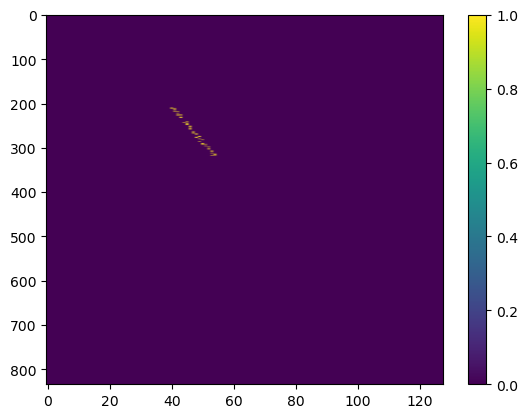

In [169]:
plt.imshow(virtual_space, aspect='auto')
plt.colorbar()

# Convert to spacial domain

In [170]:
max_depth = C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2
print(f"Max depth : {max_depth} m")
max_length = params["array"]["length"] * params["array"]["pitch"]
print(f"Max length : {max_length} m")

position_matrix = np.zeros((int(max_depth / params["image"]["dz"]), int(max_length / params["image"]["dx"])))

for i in range(0, virtual_space.shape[0]):
    for j in range(0, virtual_space.shape[1]):
        if virtual_space[i][j] != 0:

            depth_idx_value = i *( 1 / params["rf"]["sampling_rate"]) * C #find the depth in meters for virtual space
            length_idx_value = j * params["array"]["pitch"] #find the length in meters for virtual space

            depth_idx = int(depth_idx_value / params["image"]["dz"]) #find the corresponding index in the image space
            length_idx = int(length_idx_value / params["image"]["dx"]) #find the corresponding index in the image space

            position_matrix[depth_idx, length_idx] = 1

Max depth : 0.010008000000000001 m
Max length : 0.01152 m


In [171]:
np.count_nonzero(position_matrix)

52

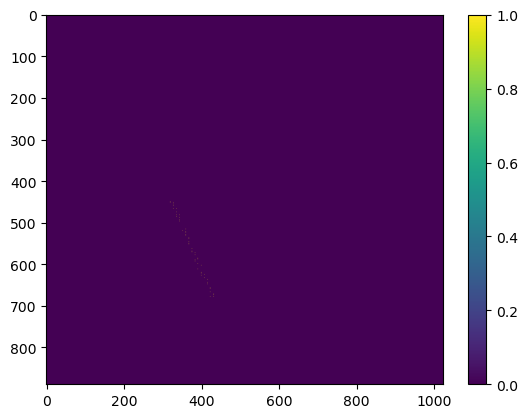

In [172]:
#plotting the position matrix
plt.imshow(position_matrix, aspect='auto', cmap="viridis")
plt.colorbar()

plt.show()


# Convert to JSON objects

In [173]:
def save_objects_to_json(matrix, parameters, new_file_path):

    parameters["objects"] = []

    for i in range(0, matrix.shape[0]):
        for j in range(0, matrix.shape[1]):
            if matrix[i][j] != 0:
                parameters["objects"].append({"position": j * parameters["image"]["dx"], "depth": i * parameters["image"]["dz"]})

    with open(new_file_path, 'w') as f:
        json.dump(parameters, f, indent=4)

    return parameters

In [174]:
new_params = save_objects_to_json(position_matrix, params, "./parameters/003_simulation_test.json")
print(f"Saved a total of {len(new_params['objects'])} objects to the json file")

Saved a total of 52 objects to the json file
